In [2]:
import importlib
import nystrom_functions
importlib.reload(nystrom_functions)

import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

from sklearn.preprocessing import StandardScaler
from KRR_utils import *
from nystrom_functions import *

In [3]:
# data setup and full KRR baseline

df = pd.read_csv("../Data/slice_localization_data.csv")
X = df.iloc[:, 1:-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

cycles = 5  
split_seed = 1  # the train/test data split remain fixed across all repetitions
method_seed = 1000  # starting seed for Nystrom methods
split_rng = np.random.default_rng(split_seed)  

# sample sizes for training and testing
n_train = 19000 #add 0
n_test = 1000

# this is the KRR lambda in (K + lambda I) * alpha = y
krr_lam = 1e-2

# sampled columns for uniform and approximate leverage
l_values = [50, 100, 200, 400, 800, 1600]

# this is the recursive parameter, not the same lamda for some reason
rec_lam_values = [1000, 2000, 5000, 10000, 20000] #add 0
rec_delta = 0.1
rec_base_size = None # for testing

# approximate leverage starts with these many uniform columns
ini_l_fixed = 100 #100

# this is a check that compares the factorized solver to an explicit solve of (K_tilde + lambda I) only used to verify the solver works
check_explicit_solve = False

ind = split_rng.choice(X.shape[0], size=n_train + n_test, replace=False)  

train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train_raw = X[train_ind]
y_train = y[train_ind]
X_test_raw = X[test_ind]
y_test = y[test_ind]

# free the complete dataset after making the fixed split 
del df, X, y

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

gamma = 1 / X_train.shape[1]

def rbf_final(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

def get_mse(y_true, y_pred):
    err = np.mean((y_true - y_pred)**2)
    return err

dataset = "CTSliceLocalization"

print("cycles =", cycles)
print("n_train =", n_train)
print("n_test =", n_test)
print("krr lambda =", krr_lam)
print("gamma =", gamma)

# full kernel direct form
start_time = time.perf_counter()
K_train = rbf_final(X_train, X_train)
K_test = rbf_final(X_test, X_train)
full_kernel_time = time.perf_counter() - start_time
full_solve_times = []

for cycle in range(cycles):
    print("full KRR cycle", cycle + 1, "of", cycles)

    start_time = time.perf_counter()

    alpha_full = np.linalg.solve(
        K_train + krr_lam*np.eye(n_train),
        y_train
    )
    y_hat_full = K_test @ alpha_full

    full_solve_times.append(time.perf_counter() - start_time)

full_solve_time = np.mean(full_solve_times)
full_solve_variance = np.var(full_solve_times, ddof=1)
full_solve_std = np.std(full_solve_times, ddof=1)
full_total_time = full_kernel_time + full_solve_time
full_mse = get_mse(y_test, y_hat_full)

K_norm = np.linalg.norm(K_train, ord="fro")
y_norm = np.linalg.norm(y_train)
alpha_norm = np.linalg.norm(alpha_full)

print("full KRR mse =", full_mse)
print("full kernel time =", full_kernel_time)
print("mean full solve time =", full_solve_time)
print("full solve time variance =", full_solve_variance)
print("full solve time std =", full_solve_std)
print("full total time with mean solve time =", full_total_time)

cycles = 5
n_train = 19000
n_test = 1000
krr lambda = 0.01
gamma = 0.0026041666666666665
full KRR cycle 1 of 5
full KRR cycle 2 of 5
full KRR cycle 3 of 5
full KRR cycle 4 of 5
full KRR cycle 5 of 5
full KRR mse = 1.641115422766367
full kernel time = 7.682311099999879
mean full solve time = 17.915308539999934
full solve time variance = 0.26705428561710304
full solve time std = 0.5167729536431865
full total time with mean solve time = 25.597619639999813


In [4]:
# uniform and approximate leverage experiments

rows = []

for cycle in range(1, cycles + 1):
    print("cycle", cycle, "of", cycles, " uniform and approximate leverage")
    uniform_rng = np.random.default_rng(method_seed + cycle)
    approx_rng = np.random.default_rng(method_seed + cycle + 1000)

    for l in l_values:
        print("")
        print("l =", l)

        # uniform sampling
        
        print("uniform")

        start_time = time.perf_counter()
        uni_ind = uniform_sampling(n_train, l, uniform_rng)  
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_uni, y_hat_uni, U_uni, eig_uni, C_uni, W_uni = solver(
            X_train,
            rbf_final,
            uni_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_uni = (U_uni * eig_uni) @ U_uni.T

        uni_kernel_err = np.linalg.norm(K_train - K_uni, ord="fro") / K_norm
        uni_alpha_err = np.linalg.norm(alpha_full - alpha_uni) / alpha_norm
        uni_mse = get_mse(y_test, y_hat_uni)

        if check_explicit_solve:
            alpha_uni_explicit = np.linalg.solve(K_uni + krr_lam*np.eye(n_train), y_train)
            uni_solver_err = np.linalg.norm(alpha_uni - alpha_uni_explicit) / np.linalg.norm(alpha_uni_explicit)
        else:
            uni_solver_err = np.nan

        rows.append([
            cycle,
            l,
            "uniform",
            np.nan, #empty column for rls
            uni_kernel_err,
            uni_alpha_err,
            uni_solver_err,
            uni_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("kernel error =", uni_kernel_err)
        print("alpha error =", uni_alpha_err)
        print("test mse =", uni_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)


        # approximate leverage sampling
        
        print("approx leverage")

        ini_l = min(ini_l_fixed, max(1, l // 2))
        extra_l = l - ini_l

        start_time = time.perf_counter()
        app_ind, app_scores, ini_ind = approximate_leverage_kernel(
            X_train,
            rbf_final,
            ini_l,
            extra_l,
            approx_rng
        )
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_app, y_hat_app, U_app, eig_app, C_app, W_app = solver(
            X_train,
            rbf_final,
            app_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_app = (U_app * eig_app) @ U_app.T

        app_kernel_err = np.linalg.norm(K_train - K_app, ord="fro") / K_norm
        app_alpha_err = np.linalg.norm(alpha_full - alpha_app) / alpha_norm
        app_mse = get_mse(y_test, y_hat_app)

        if check_explicit_solve:
            alpha_app_explicit = np.linalg.solve(K_app + krr_lam*np.eye(n_train), y_train)
            app_solver_err = np.linalg.norm(alpha_app - alpha_app_explicit) / np.linalg.norm(alpha_app_explicit)
        else:
            app_solver_err = np.nan

        rows.append([
            cycle,
            len(app_ind),
            "approx leverage",
            np.nan,
            app_kernel_err,
            app_alpha_err,
            app_solver_err,
            app_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("kernel error =", app_kernel_err)
        print("alpha error =", app_alpha_err)
        print("test mse =", app_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)

cycle 1 of 5  uniform and approximate leverage

l = 50
uniform
kernel error = 0.13621893102176888
alpha error = 50.76916284971112
test mse = 142.7872904495535
sample_time = 0.0005957999997008301
solve_time = 0.1231551999999283
time = 0.12375099999962913
approx leverage
kernel error = 0.15096916574795813
alpha error = 53.136524847846985
test mse = 154.4105820192378
sample_time = 0.12620400000014342
solve_time = 0.09366780000027575
time = 0.21987180000041917

l = 100
uniform
kernel error = 0.0994184898959291
alpha error = 40.722317862154426
test mse = 90.64711599214765
sample_time = 0.00012419999984558672
solve_time = 0.24082060000000638
time = 0.24094479999985197
approx leverage
kernel error = 0.10672454378449212
alpha error = 40.75103325547101
test mse = 85.12728190629178
sample_time = 0.17035359999999855
solve_time = 0.21078239999997095
time = 0.3811359999999695

l = 200
uniform
kernel error = 0.06795264108210682
alpha error = 37.577835128472664
test mse = 84.17205411620903
sample_tim

In [5]:
# recursive RLS
k_diag_train = np.diag(K_train).copy()

for cycle in range(1, cycles + 1):
    print("main experiment cycle", cycle, "of", cycles, "- recursive RLS")
    recursive_rng = np.random.default_rng(method_seed + cycle + 2000)

    for rec_lam in rec_lam_values:
        print("")
        print("recursive RLS, rec_lam =", rec_lam)

        start_time = time.perf_counter()
        rec_ind, rec_weight = recursive_nystrom(
            X_train,
            rbf_final,
            rec_lam,
            rec_delta,
            recursive_rng,
            k_diag_train,
            rec_base_size
        )
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_rec, y_hat_rec, U_rec, eig_rec, C_rec, W_rec = solver(
            X_train,
            rbf_final,
            rec_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_rec = (U_rec * eig_rec) @ U_rec.T

        rec_kernel_err = np.linalg.norm(K_train - K_rec, ord="fro") / K_norm
        rec_alpha_err = np.linalg.norm(alpha_full - alpha_rec) / alpha_norm
        rec_mse = get_mse(y_test, y_hat_rec)

        if check_explicit_solve:
            alpha_rec_explicit = np.linalg.solve(K_rec + krr_lam*np.eye(n_train), y_train)
            rec_solver_err = np.linalg.norm(alpha_rec - alpha_rec_explicit) / np.linalg.norm(alpha_rec_explicit)
        else:
            rec_solver_err = np.nan

        rows.append([
            cycle,
            len(rec_ind),
            "recursive RLS",
            rec_lam,
            rec_kernel_err,
            rec_alpha_err,
            rec_solver_err,
            rec_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("selected columns =", len(rec_ind))
        print("kernel error =", rec_kernel_err)
        print("alpha error =", rec_alpha_err)
        print("test mse =", rec_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)

main experiment cycle 1 of 5 - recursive RLS

recursive RLS, rec_lam = 1000
selected columns = 1980
kernel error = 0.017685045884314778
alpha error = 15.966972719085174
test mse = 16.664915514331334
sample_time = 3.2016866000003574
solve_time = 10.741615899999942
time = 13.9433025000003

recursive RLS, rec_lam = 2000
selected columns = 931
kernel error = 0.028918516016331868
alpha error = 20.10923518935922
test mse = 25.96769750083486
sample_time = 1.0786293000001024
solve_time = 5.446915300000001
time = 6.525544600000103

recursive RLS, rec_lam = 5000
selected columns = 329
kernel error = 0.05410787952653701
alpha error = 32.59958341897059
test mse = 60.54311474957078
sample_time = 0.8705089000000044
solve_time = 1.2068496000001687
time = 2.077358500000173

recursive RLS, rec_lam = 10000
selected columns = 158
kernel error = 0.07758149206706283
alpha error = 40.28975267014701
test mse = 95.84434993329133
sample_time = 0.7872299000000567
solve_time = 0.38159509999968577
time = 1.168824

In [6]:
# table

columns = [
    "cycle",
    "l",
    "method",
    "rec_lam",
    "relative_kernel_error",
    "relative_alpha_error",
    "explicit_solver_error",
    "test_mse",
    "sample_time",
    "solve_time",
    "total_time"
]

results = pd.DataFrame(rows, columns=columns)
results["test_rmse"] = np.sqrt(results["test_mse"])  # RMSE is calculated separately for every trial
results["relative_excess_rmse"] = (results["test_rmse"] - np.sqrt(full_mse)) / np.sqrt(full_mse)
results["parameter"] = results["l"]
results.loc[results["method"] == "recursive RLS", "parameter"] = results.loc[results["method"] == "recursive RLS", "rec_lam"]

summary_results = results.groupby(["method", "parameter"], as_index=False).agg(
    l_mean=("l", "mean"),  # recursive RLS is placed at its average selected column count
    l_variance=("l", "var"),
    l_std=("l", "std"),
    relative_kernel_error_mean=("relative_kernel_error", "mean"),  # empirical expectation
    relative_kernel_error_variance=("relative_kernel_error", "var"),  # sample variance
    relative_kernel_error_std=("relative_kernel_error", "std"),
    relative_alpha_error_mean=("relative_alpha_error", "mean"),
    relative_alpha_error_variance=("relative_alpha_error", "var"),
    relative_alpha_error_std=("relative_alpha_error", "std"),
    test_mse_mean=("test_mse", "mean"),
    test_mse_variance=("test_mse", "var"),
    test_mse_std=("test_mse", "std"),
    test_rmse_mean=("test_rmse", "mean"),
    test_rmse_variance=("test_rmse", "var"),
    test_rmse_std=("test_rmse", "std"),
    relative_excess_rmse_mean=("relative_excess_rmse", "mean"),
    relative_excess_rmse_variance=("relative_excess_rmse", "var"),
    relative_excess_rmse_std=("relative_excess_rmse", "std"),
    sample_time_mean=("sample_time", "mean"),
    sample_time_variance=("sample_time", "var"),
    sample_time_std=("sample_time", "std"),
    solve_time_mean=("solve_time", "mean"),
    solve_time_variance=("solve_time", "var"),
    solve_time_std=("solve_time", "std"),
    total_time_mean=("total_time", "mean"),
    total_time_variance=("total_time", "var"),
    total_time_std=("total_time", "std")
)

results.to_csv("../Results/" + dataset + "final_cycleed_raw_results.csv", index=False)
summary_results.to_csv("../Results/" + dataset + "final_cycleed_summary_results.csv", index=False)

print("individual cycleed runs")
display(results)
print("expectation, variance, and standard deviation")
summary_results

individual cycleed runs


,cycle,l,method,rec_lam,relative_kernel_error,relative_alpha_error,explicit_solver_error,test_mse,sample_time,solve_time,total_time,test_rmse,relative_excess_rmse,parameter
0,1,50,uniform,NaN,0.136219,50.769163,NaN,142.787290,0.000596,0.123155,0.123751,11.949364,8.327714,50
1,1,50,approx leverage,NaN,0.150969,53.136525,NaN,154.410582,0.126204,0.093668,0.219872,12.426205,8.699938,50
2,1,100,uniform,NaN,0.099418,40.722318,NaN,90.647116,0.000124,0.240821,0.240945,9.520878,6.432030,100
3,1,100,approx leverage,NaN,0.106725,40.751033,NaN,85.127282,0.170354,0.210782,0.381136,9.226445,6.202194,100
4,1,200,uniform,NaN,0.067953,37.577835,NaN,84.172054,0.000293,0.613518,0.613812,9.174533,6.161672,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,5,1995,recursive RLS,1000.0,0.016878,14.102213,NaN,14.543010,2.471948,10.440434,12.912382,3.813530,1.976854,1000
81,5,882,recursive RLS,2000.0,0.030707,21.361817,NaN,28.358970,1.632245,4.043076,5.675321,5.325314,3.156958,2000
82,5,344,recursive RLS,5000.0,0.052857,31.342239,NaN,56.738583,1.167484,1.422267,2.589752,7.532502,4.879896,5000
83,5,156,recursive RLS,10000.0,0.076687,39.570069,NaN,89.501610,0.779755,0.407202,1.186957,9.460529,6.384921,10000


expectation, variance, and standard deviation


,method,parameter,l_mean,l_variance,l_std,relative_kernel_error_mean,relative_kernel_error_variance,relative_kernel_error_std,relative_alpha_error_mean,relative_alpha_error_variance,...,relative_excess_rmse_std,sample_time_mean,sample_time_variance,sample_time_std,solve_time_mean,solve_time_variance,solve_time_std,total_time_mean,total_time_variance,total_time_std
0,approx leverage,50,50.0,0.0,0.000000,0.150717,5.231312e-06,0.002287,50.864115,6.913753,...,0.414842,0.135307,1.990058e-04,0.014107,0.125300,0.000375,0.019376,0.260607,0.000867,0.029448
1,approx leverage,100,100.0,0.0,0.000000,0.108272,1.153423e-05,0.003396,43.263193,3.194311,...,0.487886,0.175763,1.703672e-04,0.013052,0.214030,0.000021,0.004637,0.389793,0.000195,0.013948
2,approx leverage,200,200.0,0.0,0.000000,0.076938,7.157415e-06,0.002675,39.028487,4.854625,...,0.516405,0.254444,8.001778e-05,0.008945,0.535762,0.031696,0.178032,0.790206,0.030651,0.175075
3,approx leverage,400,400.0,0.0,0.000000,0.053853,6.680416e-06,0.002585,32.670802,4.207335,...,0.376845,0.256397,5.891818e-04,0.024273,2.340424,0.524470,0.724203,2.596821,0.544728,0.738057
4,approx leverage,800,800.0,0.0,0.000000,0.038221,5.009978e-06,0.002238,26.756100,4.081285,...,0.413365,0.266548,7.160730e-05,0.008462,4.068717,1.220320,1.104681,4.335265,1.211374,1.100624
5,approx leverage,1600,1600.0,0.0,0.000000,0.025968,5.616537e-06,0.002370,21.089540,1.677862,...,0.335641,0.260281,2.690226e-04,0.016402,7.989562,0.663087,0.814301,8.249843,0.661636,0.813410
6,recursive RLS,1000,2019.6,4974.8,70.532262,0.016994,3.694540e-07,0.000608,14.792711,0.929382,...,0.096709,2.526736,1.472834e-01,0.383775,10.878941,0.277206,0.526504,13.405676,0.309313,0.556159
7,recursive RLS,2000,939.0,1411.5,37.569935,0.029125,1.121265e-06,0.001059,21.123578,2.193620,...,0.378132,1.572391,8.790106e-02,0.296481,3.809489,0.981016,0.990462,5.381880,0.535832,0.732006
8,recursive RLS,5000,338.4,403.8,20.094775,0.053461,4.517254e-06,0.002125,31.972362,2.878125,...,0.321044,0.972606,1.310907e-02,0.114495,1.484144,0.170307,0.412683,2.456750,0.173963,0.417088
9,recursive RLS,10000,147.6,131.3,11.458621,0.080884,1.777928e-05,0.004217,39.961170,2.646594,...,0.340409,0.779819,2.051784e-03,0.045297,0.343421,0.003154,0.056163,1.123240,0.005973,0.077285


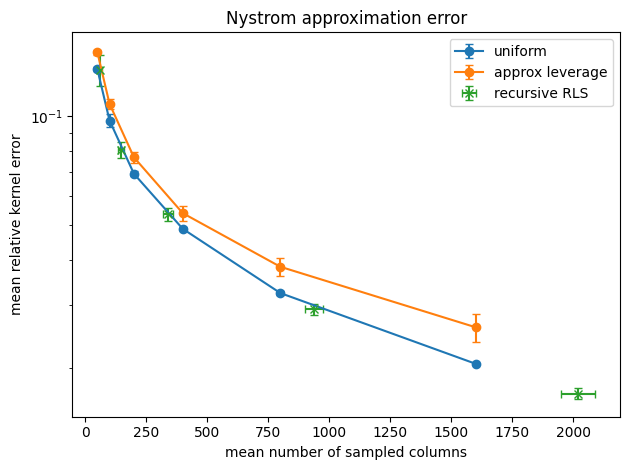

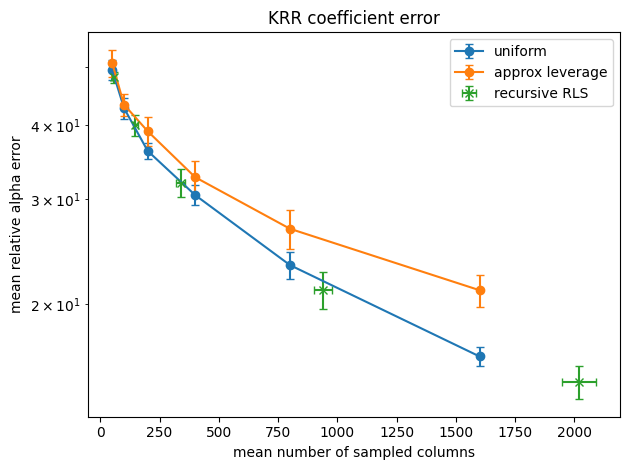

In [11]:
# main plots

plot_df = summary_results.copy()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_kernel_error_mean"], yerr=sub["relative_kernel_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_kernel_error_mean"], xerr=sub["l_std"], yerr=sub["relative_kernel_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative kernel error")
plt.title("Nystrom approximation error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_kernel_error_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_alpha_error_mean"], yerr=sub["relative_alpha_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_alpha_error_mean"], xerr=sub["l_std"], yerr=sub["relative_alpha_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative alpha error")
plt.title("KRR coefficient error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_alpha_error_vs_l.pdf")
plt.show()

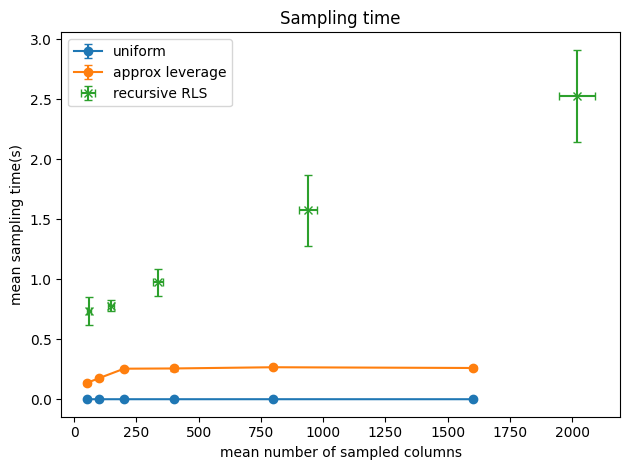

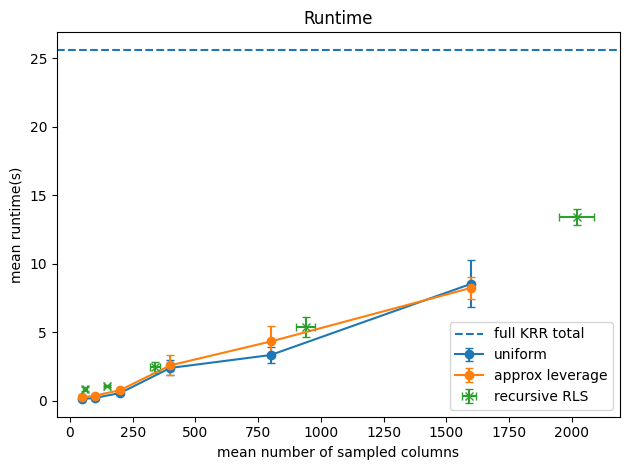

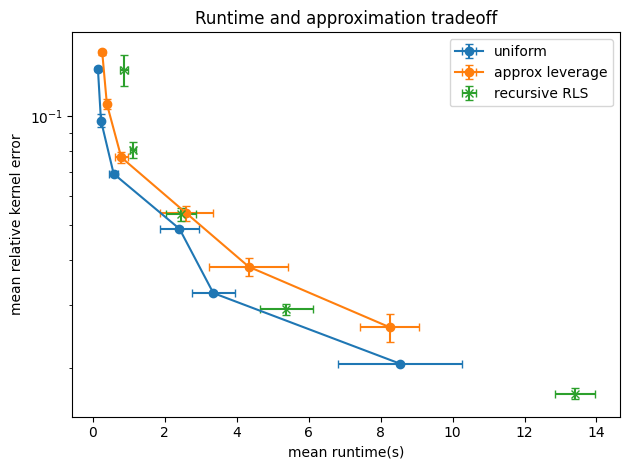

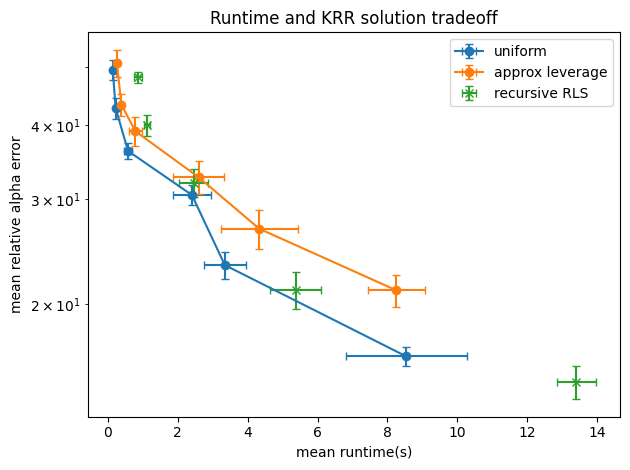

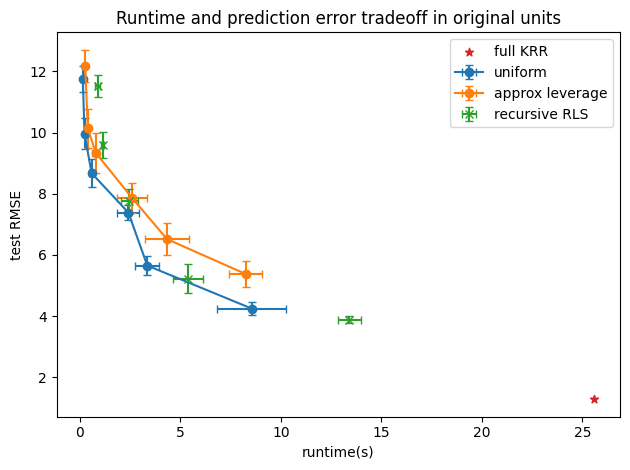

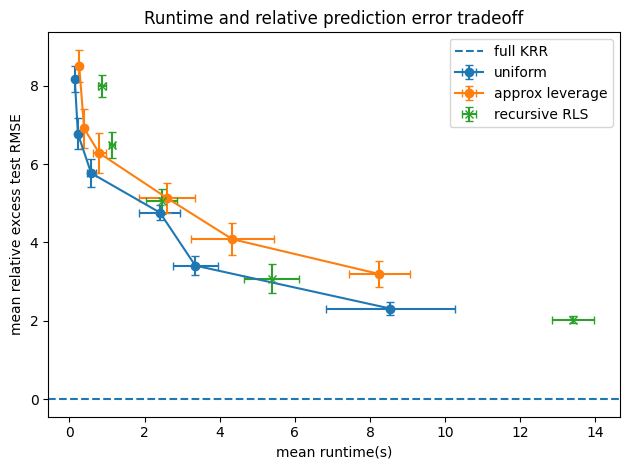

In [16]:
# runtime plots

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["sample_time_mean"], yerr=sub["sample_time_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["sample_time_mean"], xerr=sub["l_std"], yerr=sub["sample_time_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean sampling time(s)")
plt.title("Sampling time")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_sample_time_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["total_time_mean"], yerr=sub["total_time_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["total_time_mean"], xerr=sub["l_std"], yerr=sub["total_time_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(full_total_time, linestyle="--", label="full KRR total")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean runtime(s)")
plt.title("Runtime")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_total_time_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_kernel_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_kernel_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_kernel_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_kernel_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative kernel error")
plt.title("Runtime and approximation tradeoff")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_kernel_error_tradeoff.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_alpha_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_alpha_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_alpha_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_alpha_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative alpha error")
plt.title("Runtime and KRR solution tradeoff")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_alpha_error_tradeoff.pdf")
plt.show()
plt.figure()

for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")

    plt.errorbar(
        sub["total_time_mean"],
        sub["test_rmse_mean"],
        xerr=sub["total_time_std"],
        yerr=sub["test_rmse_std"],
        marker="o",
        capsize=3,
        label=method
    )

sub = plot_df[plot_df["method"] == "recursive RLS"]

plt.errorbar(
    sub["total_time_mean"],
    sub["test_rmse_mean"],
    xerr=sub["total_time_std"],
    yerr=sub["test_rmse_std"],
    fmt="x",
    capsize=3,
    linestyle="none",
    label="recursive RLS"
)

plt.scatter(
    [full_total_time],
    [np.sqrt(full_mse)],
    marker="*",
    color="tab:red",
    label="full KRR"
)

plt.xlabel("runtime(s)")
plt.ylabel("test RMSE")
plt.title("Runtime and prediction error tradeoff in original units")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_test_rmse_tradeoff.pdf")
plt.show()
plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_excess_rmse_mean"], xerr=sub["total_time_std"], yerr=sub["relative_excess_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_excess_rmse_mean"], xerr=sub["total_time_std"], yerr=sub["relative_excess_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(0, linestyle="--", label="full KRR")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative excess test RMSE")
plt.title("Runtime and relative prediction error tradeoff")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_runtime_relative_excess_rmse_tradeoff.pdf")
plt.show()

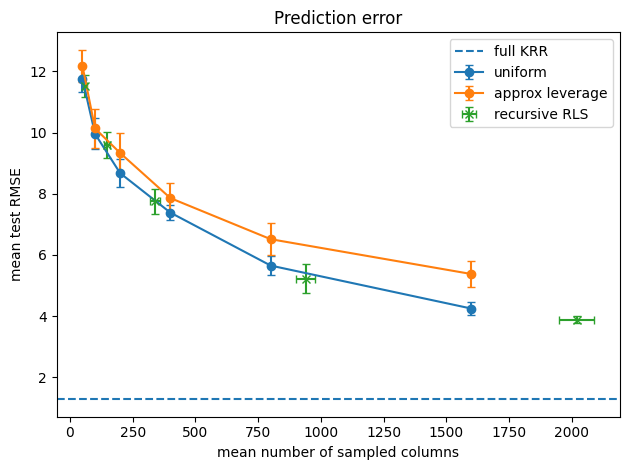

In [13]:
# prediction error in original units

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["test_rmse_mean"], yerr=sub["test_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["test_rmse_mean"], xerr=sub["l_std"], yerr=sub["test_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(np.sqrt(full_mse), linestyle="--", label="full KRR")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean test RMSE")
plt.title("Prediction error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_test_rmse_vs_l.pdf")
plt.show()

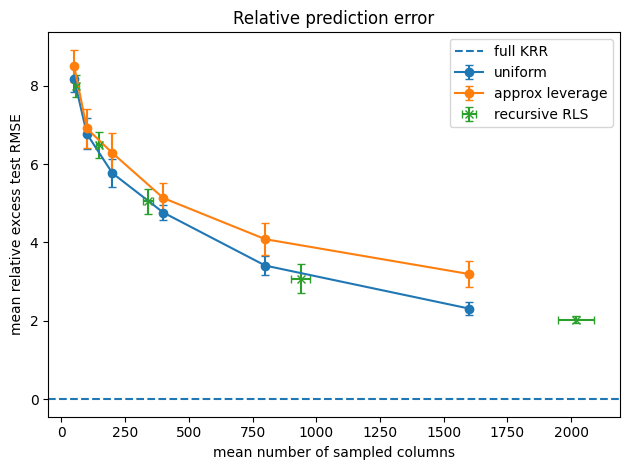

In [14]:
# prediction error check

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_excess_rmse_mean"], yerr=sub["relative_excess_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_excess_rmse_mean"], xerr=sub["l_std"], yerr=sub["relative_excess_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(0, linestyle="--", label="full KRR")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative excess test RMSE")
plt.title("Relative prediction error")
plt.legend()
plt.tight_layout()
plt.savefig("../Results/" + dataset + "final_relative_excess_rmse_vs_l.pdf")
plt.show()